# 2. Model selection

**Protocol.** The train window (first 70% of time) is cut into 7 chunks. Four rolling-origin folds fit each candidate on everything before a chunk and validate on that chunk. Candidates are ranked by mean validation **PR-AUC** (threshold-free, robust to the ~3% class balance) on the rows the detector may flag. Only **unsupervised** models can be deployed (real toll data has no labels until analysts confirm alerts); supervised models are fitted for reference, to measure *headroom*. The winner is the **cheapest** deployable model that is **not significantly worse** than the best (paired comparison across folds, 1 standard error). The calibration and test windows are never read.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve().parents[1]              # notebooks live in ml/notebooks
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / "ml"))
import common as C, model_zoo as Z
from common import cfg
from data_loader import load_plazas, load_transactions, validate
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
plazas = load_plazas()
df = load_transactions(plazas=plazas)              # validated, time-ordered, clean index
splits = C.split_time(df)
specs = C.detector_specs(plazas)
sel = json.loads(cfg.SELECTION_JSON.read_text()); print(sel["protocol"]["fold_rows"])

[{'fit': 14910, 'validate': 4970}, {'fit': 19880, 'validate': 4970}, {'fit': 24850, 'validate': 4969}, {'fit': 29819, 'validate': 4969}]


## Leaderboard (validation PR-AUC, mean +- sd over 4 folds)

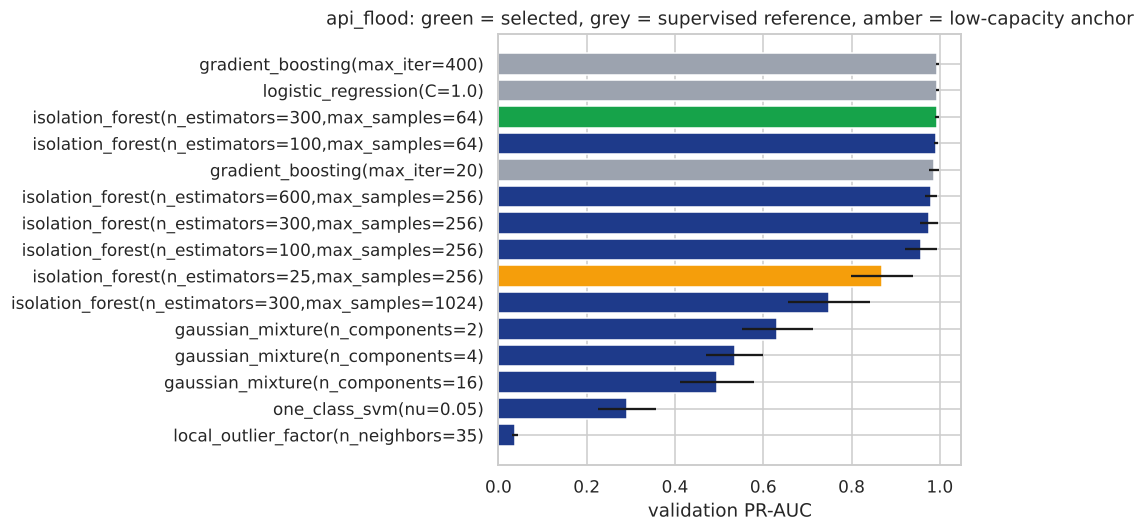

api_flood: selected isolation_forest(n_estimators=300,max_samples=64) | statistically tied with best: ['isolation_forest(n_estimators=300,max_samples=64)'] | headroom vs supervised +0.001


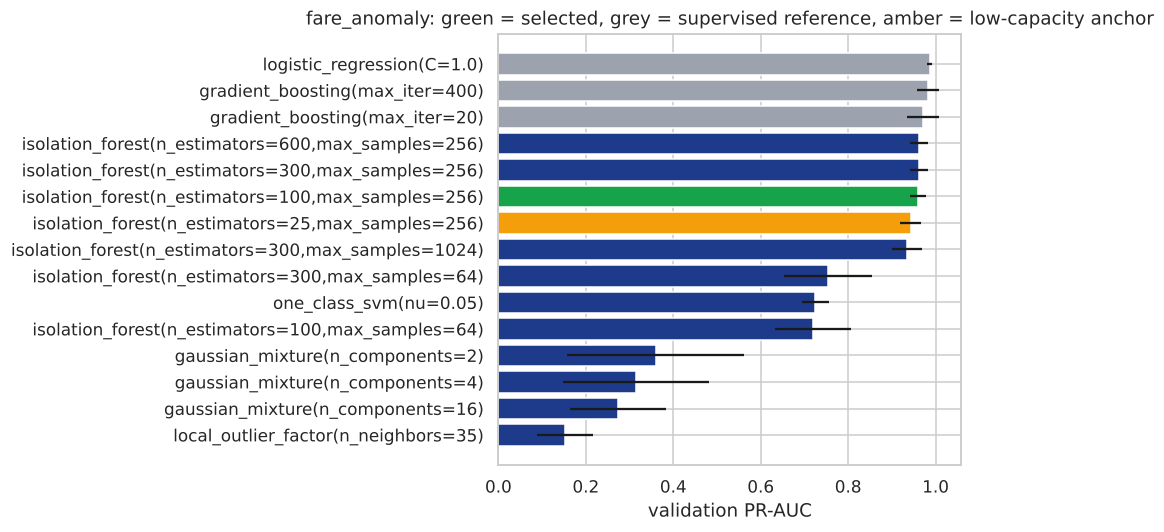

fare_anomaly: selected isolation_forest(n_estimators=100,max_samples=256) | statistically tied with best: ['isolation_forest(n_estimators=600,max_samples=256)', 'isolation_forest(n_estimators=100,max_samples=256)', 'isolation_forest(n_estimators=300,max_samples=256)'] | headroom vs supervised +0.026


In [2]:
for name, d in sel["detectors"].items():
    rows = sorted([c for c in d["candidates"] if "error" not in c], key=lambda c: c["val_pr_auc"])
    colors = ["#16A34A" if c["id"] == d["selected"]["id"] else "#9CA3AF" if c["supervised"] else "#F59E0B" if c["anchor"] else "#1E3A8A" for c in rows]
    fig, ax = plt.subplots(figsize=(9, 5)); ax.barh([c["id"] for c in rows], [c["val_pr_auc"] for c in rows], xerr=[c["val_pr_auc_sd"] for c in rows], color=colors)
    ax.set_title(f"{name}: green = selected, grey = supervised reference, amber = low-capacity anchor"); ax.set_xlabel("validation PR-AUC"); plt.tight_layout(); plt.show()
    print(f"{name}: selected {d['selected']['id']} | statistically tied with best: {d['indistinguishable_from_best']} | headroom vs supervised {d['headroom_vs_supervised_pr_auc']:+.3f}")

## Why Isolation Forest wins: contamination masking
The training data contains ~3% anomalies, and they recur (floods come in bursts, tampering has a pattern). Density-based models (LOF, GMM) treat a recurring pattern as a *normal mode*. Isolation Forest builds each tree on a small random subsample, so a rare pattern stays easy to isolate. Proof: give LOF a *clean* training set (anomaly rows removed, which is only possible here because the data is labelled) and it recovers.

In [3]:
from sklearn.metrics import average_precision_score
spec = specs["api_flood"]; train, val = C.selection_folds(splits["train"])[-1]   # last selection fold: fit rows -> validation chunk (calibration/test never touched)
Xtr, Xva = spec["featurize"](train), spec["featurize"](val); ytr, yva = C.labels(train, spec), C.labels(val, spec)
res = {}
for label, X, mask in [("LOF, realistic (contaminated) training set", Xtr, slice(None)), ("LOF, clean training set (labels used, diagnostic only)", Xtr[~ytr], slice(None))]:
    m = Z.build("local_outlier_factor", dict(n_neighbors=35)).fit(X, None, gate_col="ctx_req"); g = C.gate_mask(spec, m, Xva); res[label] = average_precision_score(yva[g], m.score(Xva)[g])
m = Z.build("isolation_forest", dict(n_estimators=300, max_samples=64)).fit(Xtr, None, gate_col="ctx_req"); g = C.gate_mask(spec, m, Xva); res["Isolation Forest, realistic (contaminated) training set"] = average_precision_score(yva[g], m.score(Xva)[g])
print(pd.Series(res).round(3).to_string()); print(f"base rate (gated rows): {yva[g].mean():.3f}")

LOF, realistic (contaminated) training set                 0.037
LOF, clean training set (labels used, diagnostic only)     0.782
Isolation Forest, realistic (contaminated) training set    0.995
base rate (gated rows): 0.039


## The best subsample size is different for each detector
Floods are a tight, short cluster: a small subsample (64) isolates them best and a large one (2048) swamps them. Fare anomalies sit *between* dense legitimate clusters and need a larger subsample (256) to model those clusters. This is why each detector is tuned on its own.

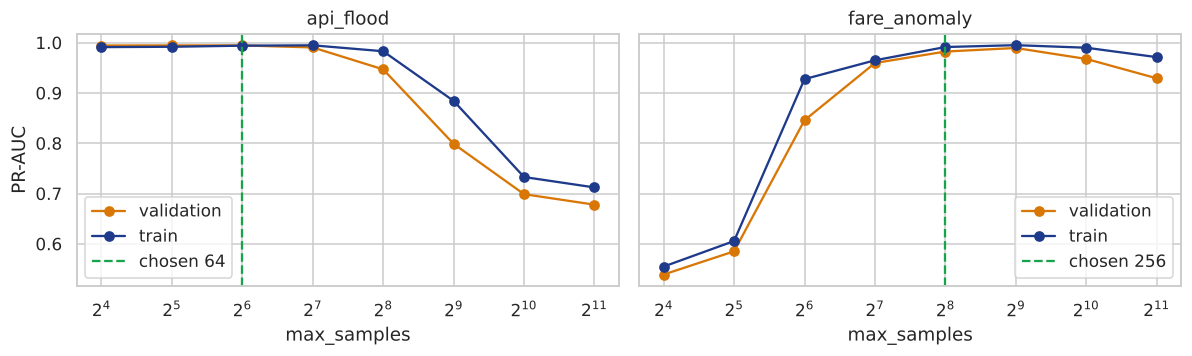

In [4]:
dg = json.loads(cfg.DIAGNOSTICS_JSON.read_text())
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for a, (name, e) in zip(ax, dg["detectors"].items()):
    c = e["data"]["capacity_curves"]["max_samples"]; xs = [r["value"] for r in c["curve"]]
    a.plot(xs, [r["val_pr_auc"] for r in c["curve"]], "o-", color="#D97706", label="validation"); a.plot(xs, [r["train_pr_auc"] for r in c["curve"]], "o-", color="#1E3A8A", label="train")
    a.axvline(c["chosen"], color="#16A34A", ls="--", label=f"chosen {c['chosen']}"); a.set_xscale("log", base=2); a.set_title(name); a.set_xlabel("max_samples"); a.legend()
ax[0].set_ylabel("PR-AUC"); plt.tight_layout(); plt.show()

## Fold-by-fold: is the winner consistently good, or lucky on one fold?

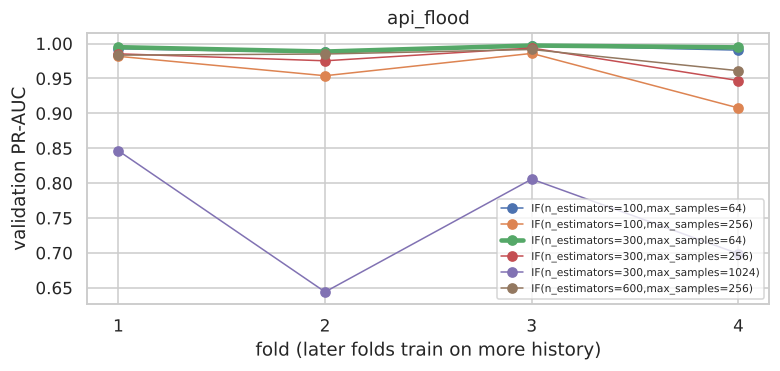

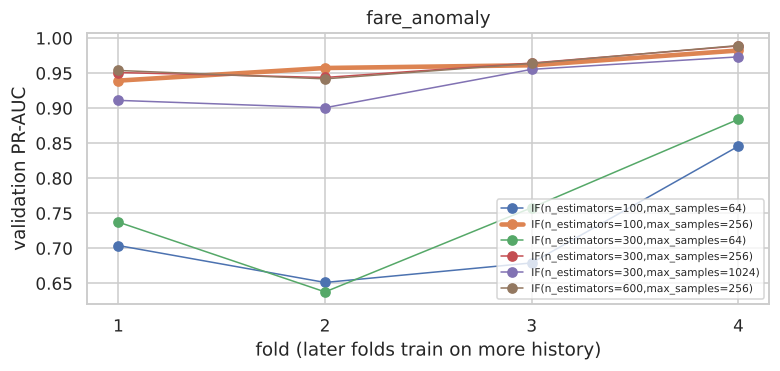

In [5]:
for name, d in sel["detectors"].items():
    fig, ax = plt.subplots(figsize=(8, 3.2))
    for c in d["candidates"]:
        if c["family"] == "isolation_forest" and "error" not in c and not c["anchor"]:
            ax.plot(range(1, 5), c["fold_val_pr_auc"], "o-", lw=3 if c["id"] == d["selected"]["id"] else 1, label=c["id"].replace("isolation_forest", "IF"))
    ax.set_xticks(range(1, 5)); ax.set_xlabel("fold (later folds train on more history)"); ax.set_ylabel("validation PR-AUC"); ax.set_title(name); ax.legend(fontsize=7, loc="lower right"); plt.show()

## Headroom: what does labelled data buy?
A supervised model on the same features is the ceiling for what labels could add. If headroom is small, the label-free model is not leaving much on the table (not underfitting). The dashboard's confirm/dismiss feedback could supply those labels later.

In [6]:
print(pd.DataFrame({n: {"selected (unsupervised)": d["selected"]["val_pr_auc"], "best supervised reference": d["best_supervised_reference"]["val_pr_auc"], "headroom": d["headroom_vs_supervised_pr_auc"]} for n, d in sel["detectors"].items()}).T.round(3))

              selected (unsupervised)  best supervised reference  headroom
api_flood                       0.994                      0.994     0.001
fare_anomaly                    0.960                      0.986     0.026
